In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# Carga de la base original
data = pd.read_csv('/content/ecommerce_customer_behavior_dataset_v2 (1).csv')
data_raw = pd.read_csv('/content/ecommerce_customer_behavior_dataset_v2 (1).csv')

# Conversión de la variable fecha
data_raw['Date'] = pd.to_datetime(data_raw['Date'])

# Copias para las distintas etapas del proyecto
data_eda = data_raw.copy()

In [ ]:
data_eda.head()

,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_000001-1,CUST_00001,2023-05-29,40,Male,Ankara,Books,29.18,1,0.00,29.18,Digital Wallet,Mobile,14,9,True,13,4
1,ORD_000001-2,CUST_00001,2023-10-12,40,Male,Ankara,Home & Garden,644.40,1,138.05,506.35,Credit Card,Desktop,14,8,True,6,2
2,ORD_000001-3,CUST_00001,2023-12-05,40,Male,Ankara,Sports,332.82,5,0.00,1664.10,Credit Card,Mobile,15,10,True,9,4
3,ORD_000002-1,CUST_00002,2023-05-11,33,Male,Istanbul,Food,69.30,5,71.05,275.45,Digital Wallet,Desktop,16,13,True,4,4
4,ORD_000002-2,CUST_00002,2023-06-16,33,Male,Istanbul,Beauty,178.15,3,0.00,534.45,Credit Card,Mobile,14,7,True,6,4


In [ ]:
Clientes_unicos = data_eda['Customer_ID'].nunique()
print('Clientes únicos: ', Clientes_unicos)

Clientes únicos:  5000


Este conjunto de datos exhaustivo contiene **5.000 transacciones de comercio electrónico** de una plataforma minorista en línea turca, que abarcan desde enero de 2023 hasta marzo de 2024. El conjunto de datos ofrece información detallada sobre la demografía de los clientes, el comportamiento de compra, las preferencias de productos y las métricas de interacción.

## Atributos `Dataset Structure`:


*   Order_ID: Identificador único para cada orden
*   Date: Fecha transacción
*   Customer_ID: Identificador de cliente
*   Age: Edad del cliente
*   Gender: Género del cliente
*   City: Ciudad del cliente
*   Product_Category: Categoría de los productos (Electrónicos, Fashion, Sports, Books, Home & Garden, Beauty, Toys, food)
*   Unit_Price: Precio unitario
*   Quantity: Unidades compradas
*   Discount_Amount: Descuento aplicado
*   Total_Amount: Importe final después de descuento (en Liras Turcas (TRY))
*   Payment_Method: Método de pago
*   Device_Type: Dispositivo con el que se realizó la compra
*   Session_Duration_Minutes: Tiempo en la web en minutos
*   Pages_Viewed: Páginas visitadas en la web
*   Is_Returning_Customer: ¿El cliente ha comprado antes?
*   Delivery_Time_Days: Duración del delivery en días
*   Customer_Rating: Satisfacción del cliente (1-5)

Se traducirá los atributos a español para agilizar la lectura

In [ ]:
# Renombrando variables
# Eliminamos Order_ID y Customer_ID porque no nos aporta al análisis
data = data.drop(columns=['Order_ID', 'Customer_ID'])
data = data.rename(columns={
    'Date': 'Fecha',
    'Age': 'Edad',
    'Gender': 'Genero',
    'City': 'Ciudad',
    'Product_Category': 'Categoria_producto',
    'Unit_Price': 'Precio_unitario',
    'Quantity': 'Cantidad',
    'Discount_Amount': 'Descuento',
    'Total_Amount': 'Monto_Total',
    'Payment_Method': 'Metodo_pago',
    'Device_Type': 'Tipo_dispositivo',
    'Session_Duration_Minutes': 'Duracion_sesion_web_min',
    'Pages_Viewed': 'Paginas_vistas',
    'Is_Returning_Customer': 'Cliente_recurrente',
    'Delivery_Time_Days': 'Tiempo_entrega',
    'Customer_Rating': 'Valoracion_cliente'})

In [ ]:
data.describe()

,Edad,Precio_unitario,Cantidad,Descuento,Monto_Total,Duracion_sesion_web_min,Paginas_vistas,Tiempo_entrega,Valoracion_cliente
count,17049.000000,17049.000000,17049.000000,17049.000000,17049.000000,17049.000000,17049.000000,17049.000000,17049.000000
mean,34.945745,447.901689,3.011379,69.788135,1277.438711,14.535633,9.003109,6.503607,3.899408
std,11.046855,722.319705,1.417027,240.704662,2358.436375,2.925524,2.259954,3.488787,1.128803
min,18.000000,5.050000,1.000000,0.000000,6.210000,4.000000,1.000000,1.000000,1.000000
25%,26.000000,73.260000,2.000000,0.000000,172.970000,13.000000,7.000000,4.000000,3.000000
50%,35.000000,174.680000,3.000000,0.000000,455.850000,15.000000,9.000000,6.000000,4.000000
75%,42.000000,494.570000,4.000000,32.710000,1267.750000,17.000000,11.000000,8.000000,5.000000
max,75.000000,7900.010000,5.000000,6538.290000,37852.050000,26.000000,18.000000,25.000000,5.000000


In [ ]:
# Tipo de datos
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17049 entries, 0 to 17048
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Fecha                    17049 non-null  object 
 1   Edad                     17049 non-null  int64  
 2   Genero                   17049 non-null  object 
 3   Ciudad                   17049 non-null  object 
 4   Categoria_producto       17049 non-null  object 
 5   Precio_unitario          17049 non-null  float64
 6   Cantidad                 17049 non-null  int64  
 7   Descuento                17049 non-null  float64
 8   Monto_Total              17049 non-null  float64
 9   Metodo_pago              17049 non-null  object 
 10  Tipo_dispositivo         17049 non-null  object 
 11  Duracion_sesion_web_min  17049 non-null  int64  
 12  Paginas_vistas           17049 non-null  int64  
 13  Cliente_recurrente       17049 non-null  bool   
 14  Tiempo_entrega        

# Análisis de outliers con el Coeficiente de Variación `CV`

In [ ]:
lista_atributos = ['Edad', 'Precio_unitario', 'Cantidad', 'Descuento',
                  'Monto_Total', 'Duracion_sesion_web_min', 'Paginas_vistas',
                  'Tiempo_entrega', 'Valoracion_cliente']

In [ ]:
CV_resumen = (data[lista_atributos].std() / data[lista_atributos].mean()) * 100
print(CV_resumen)

Edad                        31.611447
Precio_unitario            161.267466
Cantidad                    47.055749
Descuento                  344.907714
Monto_Total                184.622272
Duracion_sesion_web_min     20.126571
Paginas_vistas              25.101932
Tiempo_entrega              53.643876
Valoracion_cliente          28.948055
dtype: float64


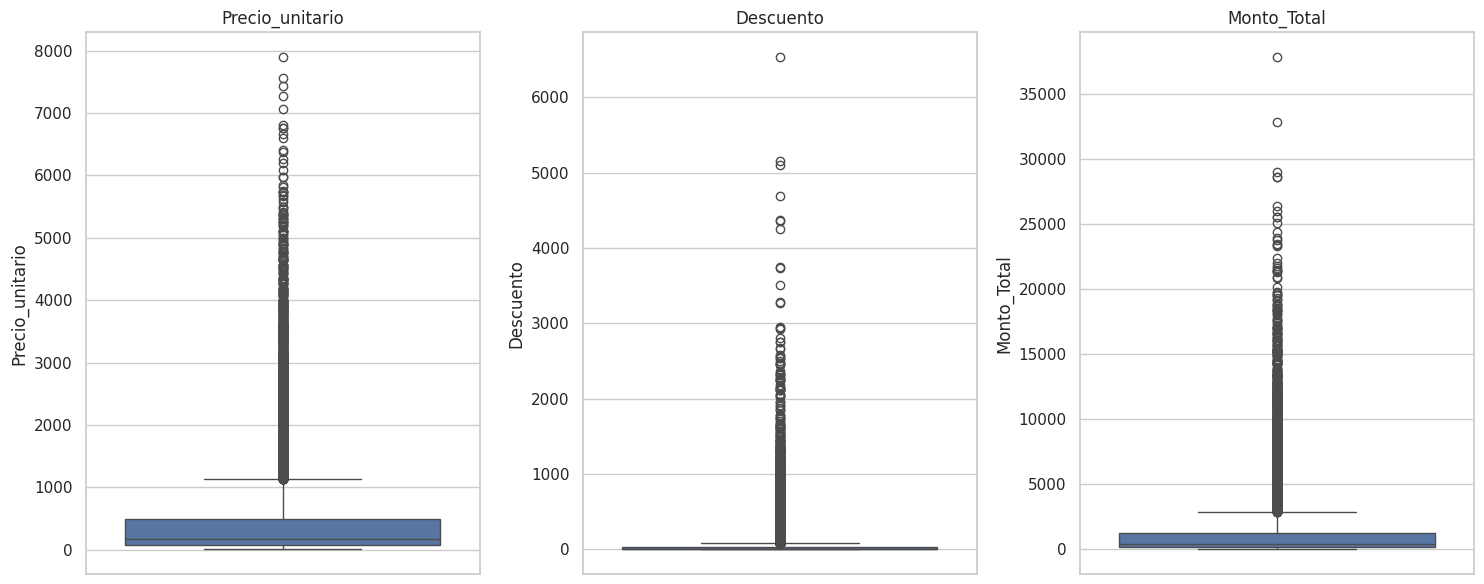

In [ ]:
# Mostrar las 3 figuras en 1 fila
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
sns.boxplot(data, y='Precio_unitario', ax=axes[0])
axes[0].set_title('Precio_unitario')
sns.boxplot(data, y='Descuento', ax=axes[1])
axes[1].set_title('Descuento')
sns.boxplot(data, y='Monto_Total', ax=axes[2])
axes[2].set_title('Monto_Total')

# Ajustamos automáticamente los márgenes para que no se superpongan los textos
plt.tight_layout()
plt.show()

# Outliers
Se aprecia bastante dispersión de datos después del tercer cuartil tanto para el precio unitario, descuento y monto total, se procede a depurar datos atípicos para un mejor análisis exploratorio

In [ ]:
columnas_limpiar = ['Precio_unitario', 'Descuento', 'Monto_Total']

# Iteración
for col in columnas_limpiar:
    # Calculamos los cuartiles y el IQR para los 3 atributos
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    # Definimos los límites
    lim_inf = Q1 - 1.5 * IQR
    lim_sup = Q3 + 1.5 * IQR

    # depuramos el dataset conservando las filas que están dentro de los límites
    data = data[(data[col] >= lim_inf) & (data[col] <= lim_sup)]

print(f"Filas restantes después de la limpieza: {len(data)}")

Filas restantes después de la limpieza: 11558


## Variables de cálculo directo
#`Cantidad` y `Descuento`

El importe final después de descuento (Total_Amount) es el resultado matemático exacto de multiplicar el precio unitario por las unidades compradas y restarle el descuento aplicado. Si se mantiene estas variables, el modelo simplemente memorizará esta ecuación en lugar de encontrar patrones predictivos en el comportamiento del cliente o de la sesión.

## Variables a posteriori - Fuga de datos temporal
#`Tiempo_entrega`
La duración del delivery en días ocurre y se registra días después de que el cliente ya pagó el importe total.

# `Valoracion_cliente`
La satisfacción del cliente solo se conoce una vez que el pedido ha sido entregado.
En un escenario de análsis profundo en tiempo real, no se tendría ninguno de estos dos datos disponibles en el momento en que el cliente está armando su carrito de compras.


## `Importe Bruto`
Al eliminar el atributo Descuento, se le devuelve los descuentos aplicados al importe total para que así mantengamos la coherencia y análisis a través del importe bruto

In [ ]:
data['Monto_Total'] = data['Monto_Total'] + data['Descuento']

In [ ]:
# Renombrando el Importe
data = data.rename(columns={
    'Monto_Total': 'Monto_Bruto'})

In [ ]:
data = data.drop(columns=["Tiempo_entrega", "Valoracion_cliente", "Cantidad", "Descuento"])
data.head()

,Fecha,Edad,Genero,Ciudad,Categoria_producto,Precio_unitario,Monto_Bruto,Metodo_pago,Tipo_dispositivo,Duracion_sesion_web_min,Paginas_vistas,Cliente_recurrente
0,2023-05-29,40,Male,Ankara,Books,29.18,29.18,Digital Wallet,Mobile,14,9,True
4,2023-06-16,33,Male,Istanbul,Beauty,178.15,534.45,Credit Card,Mobile,14,7,True
5,2023-02-27,42,Male,Konya,Toys,198.28,396.56,Credit Card,Tablet,10,9,False
9,2023-06-12,32,Male,Ankara,Toys,73.06,292.24,Credit Card,Mobile,13,12,True
10,2023-06-21,32,Male,Ankara,Fashion,529.48,529.48,Credit Card,Desktop,13,8,True


In [ ]:
data.describe()

,Edad,Precio_unitario,Monto_Bruto,Duracion_sesion_web_min,Paginas_vistas
count,11558.000000,11558.000000,11558.000000,11558.000000,11558.000000
mean,34.964094,157.242240,375.439704,14.564804,8.993338
std,11.032357,159.346172,333.680702,2.920850,2.262792
min,18.000000,5.050000,6.300000,4.000000,1.000000
25%,27.000000,53.460000,125.855000,13.000000,7.000000
50%,35.000000,102.150000,261.780000,15.000000,9.000000
75%,42.000000,201.790000,519.795000,17.000000,11.000000
max,75.000000,1121.840000,1520.750000,26.000000,18.000000


# Anomalías
Al depurar la data y eliminar sus atributos que no aportan al análisis, esta se encuentra más limpia sin datos atípicos

In [ ]:
data.isnull().sum()

,0
Fecha,0
Edad,0
Genero,0
Ciudad,0
Categoria_producto,0
Precio_unitario,0
Monto_Bruto,0
Metodo_pago,0
Tipo_dispositivo,0
Duracion_sesion_web_min,0


# Análisis del comportamiento de la data a través del `Histograma`

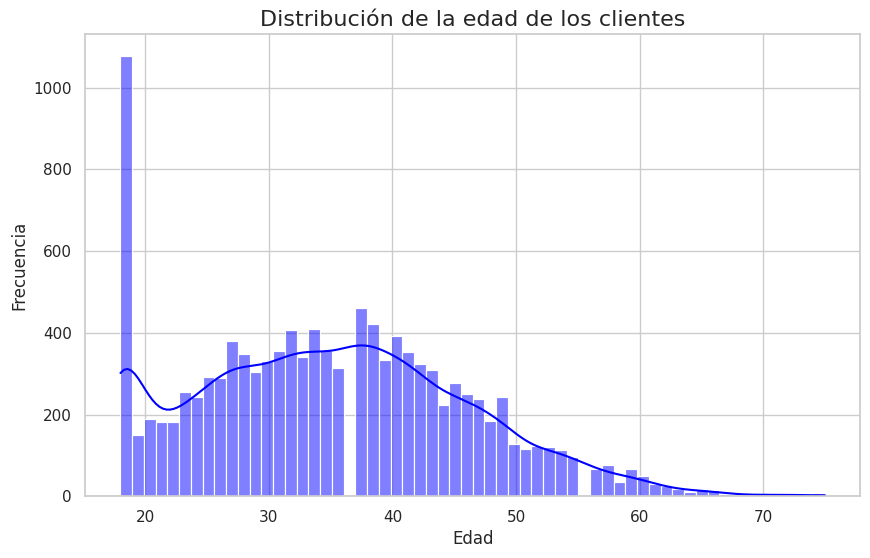

In [ ]:
sns.set_theme(style = "whitegrid")
plt.figure(figsize = (10,6))

sns.histplot(data, x = 'Edad', kde= True, bins = 60, color = 'blue')
plt.title("Distribución de la edad de los clientes", fontsize = 16)
plt.xlabel("Edad", fontsize = 12)
plt.ylabel("Frecuencia", fontsize = 12)
plt.show()

Descubrimos que hay bastante registro de clientes de 18 años y esta se resalta en el Histograma de las edades

`Restricción legal:` 18 años es típicamente la edad mínima legal para crear una cuenta, registrar una tarjeta de crédito o aceptar los términos y condiciones.

`Sesgo de ingreso:` Es muy común que usuarios menores de edad "mientan" al registrarse, seleccionando exactamente el año de nacimiento que los hace alcanzar la mayoría de edad para poder comprar.

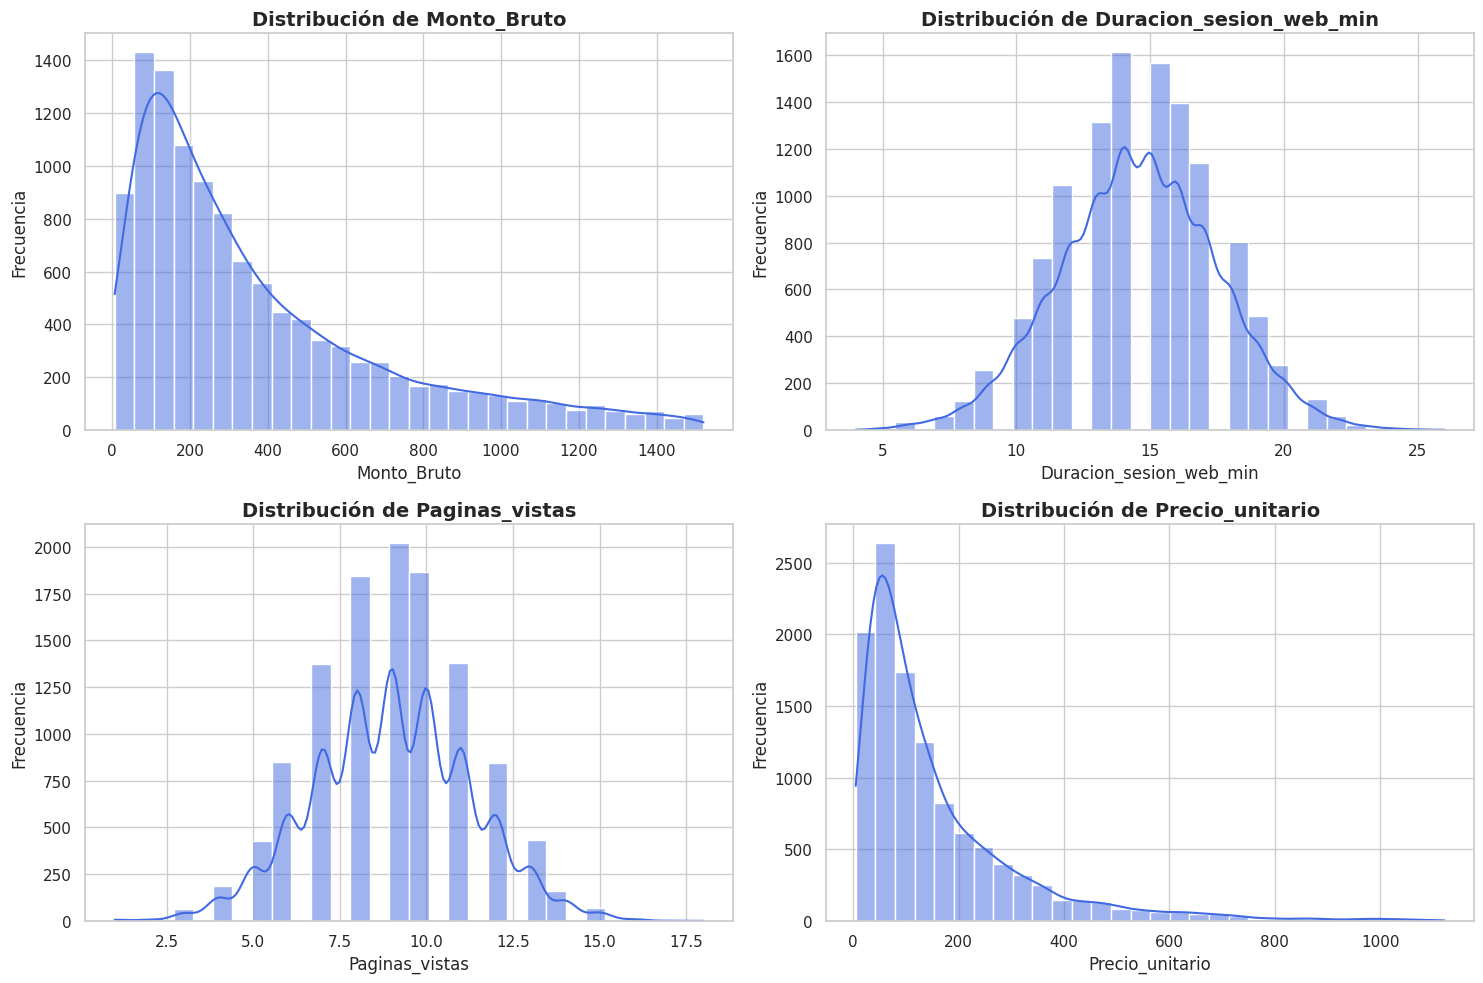

In [ ]:
columnas_hist = ['Monto_Bruto', 'Duracion_sesion_web_min', 'Paginas_vistas', 'Precio_unitario']

# Agrandamos el figsize para que los gráficos tengan espacio
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
sns.set_theme(style="whitegrid")

# "Aplanamos" la cuadrícula de ejes.
# para que el bucle for pueda recorrerlos fácilmente.
axes = axes.flatten()

# Iteramos sobre nuestra lista de variables
for i, col in enumerate(columnas_hist):
    # Graficamos indicando el espacio específico con ax=axes[i]
    sns.histplot(data, x=col, kde=True, ax=axes[i], color='royalblue', bins=30)

    # Personalizamos los títulos dinámicamente
    axes[i].set_title(f'Distribución de {col}', fontsize=14, fontweight='bold')
    axes[i].set_xlabel(col, fontsize = 12)
    axes[i].set_ylabel('Frecuencia', fontsize = 12)

# Ajustamos los márgenes para que los textos no estén superpuestos
plt.tight_layout()
plt.show()

In [ ]:
correlacion = data[['Monto_Bruto', 'Edad', 'Precio_unitario', 'Duracion_sesion_web_min', 'Paginas_vistas']].corr()
correlacion

,Monto_Bruto,Edad,Precio_unitario,Duracion_sesion_web_min,Paginas_vistas
Monto_Bruto,1.000000,-0.008843,0.696845,-0.013397,0.003166
Edad,-0.008843,1.000000,-0.007848,0.010310,-0.013215
Precio_unitario,0.696845,-0.007848,1.000000,-0.010389,0.002943
Duracion_sesion_web_min,-0.013397,0.010310,-0.010389,1.000000,0.002939
Paginas_vistas,0.003166,-0.013215,0.002943,0.002939,1.000000


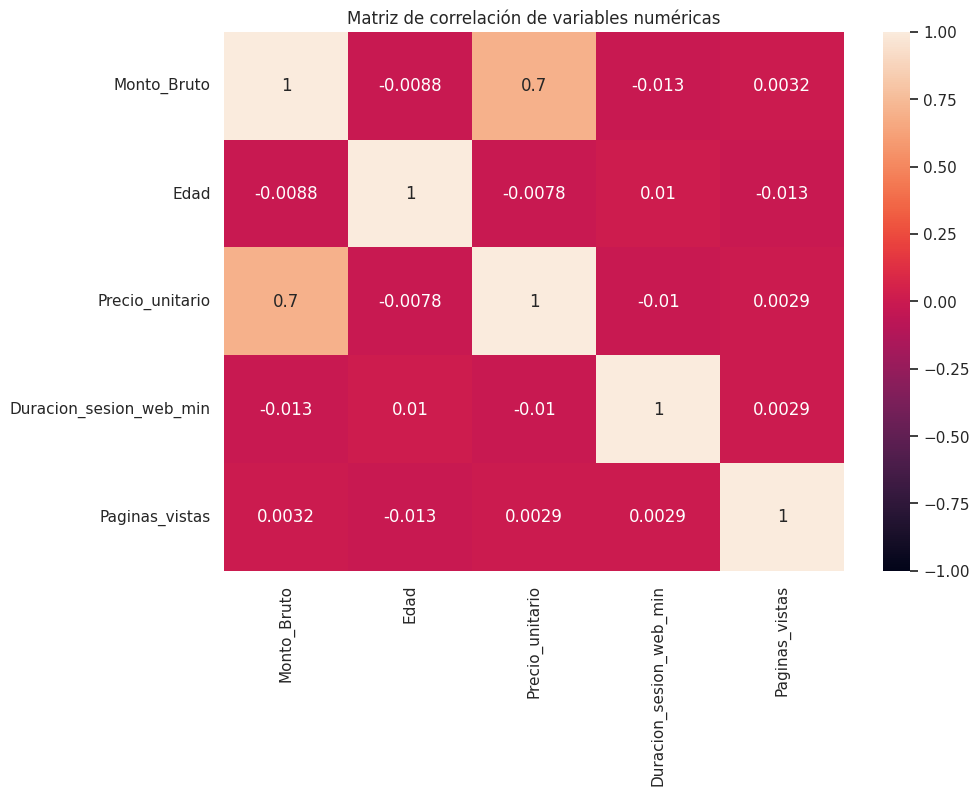

In [ ]:
# Mapa de calor de correlación

plt.figure(figsize=(10,7))
sns.heatmap(correlacion, annot=True, vmin=-1)
plt.title('Matriz de correlación de variables numéricas')
plt.show()


Hallamos correlación significante entre el Importe y el precio, esto es lógico al adquirir productos. Los demás atributos poseen baja correlación.

## Análisis del `Importe` por `Edad` y `Ciudad`

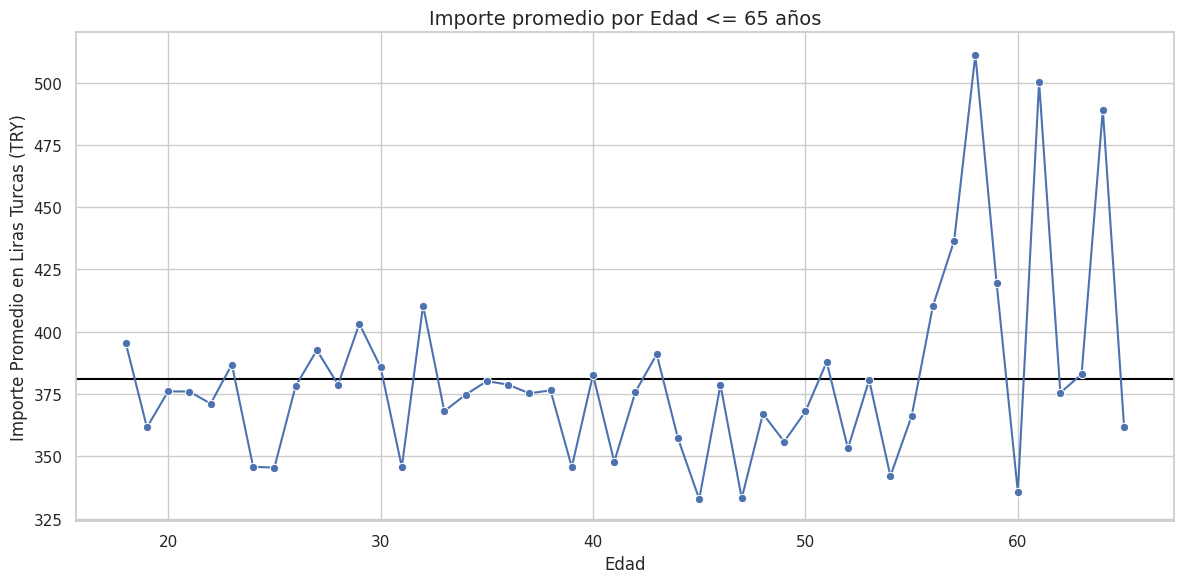

In [ ]:
# Considerando a Clientes menores e igual a 65 años

data_filtrada = data[data['Edad'] <= 65]

importe_edad = data_filtrada.groupby("Edad")["Monto_Bruto"].mean().reset_index()

plt.figure(figsize=(12, 6))

# Gráfica de la línea promedio del importe promedio de clientes <= 65 años
promedio_general = importe_edad["Monto_Bruto"].mean()
plt.axhline(
    y = promedio_general,
    color = 'black',
    linestyle = '-')

# Gráfico
sns.lineplot(
    data=importe_edad,
    x = "Edad",
    y = "Monto_Bruto",
    marker = "o")

# Títulos y etiquetas
plt.title("Importe promedio por Edad <= 65 años", fontsize=14)
plt.ylabel("Importe Promedio en Liras Turcas (TRY)")
plt.xlabel("Edad")

plt.tight_layout()
plt.show()

Los puntos que sobresalen del importe promedio no significa que clientes entre 56 y 65 años hayan tenido comportamiento errático y haya ocurrido compras de pánico entre esas edades, lo que sucede es que hubo compras caras y con poco registro, por lo que distorsiona la gráfica entre esas edades.

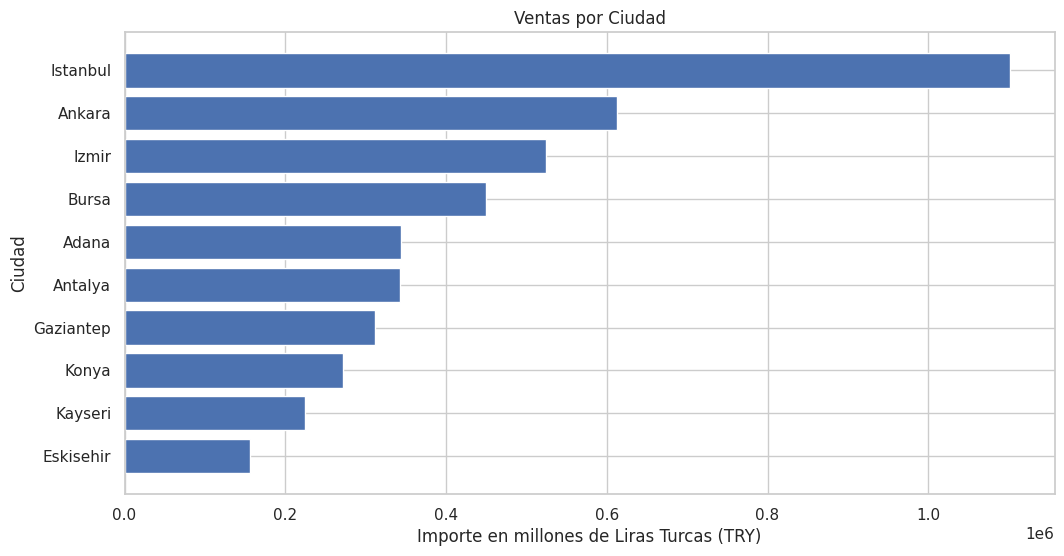

In [ ]:
# Agrupar y sumar el importe total por categoría
data_agrupada = data.groupby('Ciudad')['Monto_Bruto'].sum().reset_index()

data_agrupada = data_agrupada.sort_values(by='Monto_Bruto', ascending=True)

# Graficar usando los datos ya agrupados
plt.figure(figsize=(12, 6))
plt.barh(y = data_agrupada['Ciudad'], width = data_agrupada['Monto_Bruto'])

plt.xlabel('Importe en millones de Liras Turcas (TRY)')
plt.ylabel('Ciudad')
plt.title('Ventas por Ciudad')
plt.show()

## Análisis del `Importe` por `Producto` y `Volumen de compra`

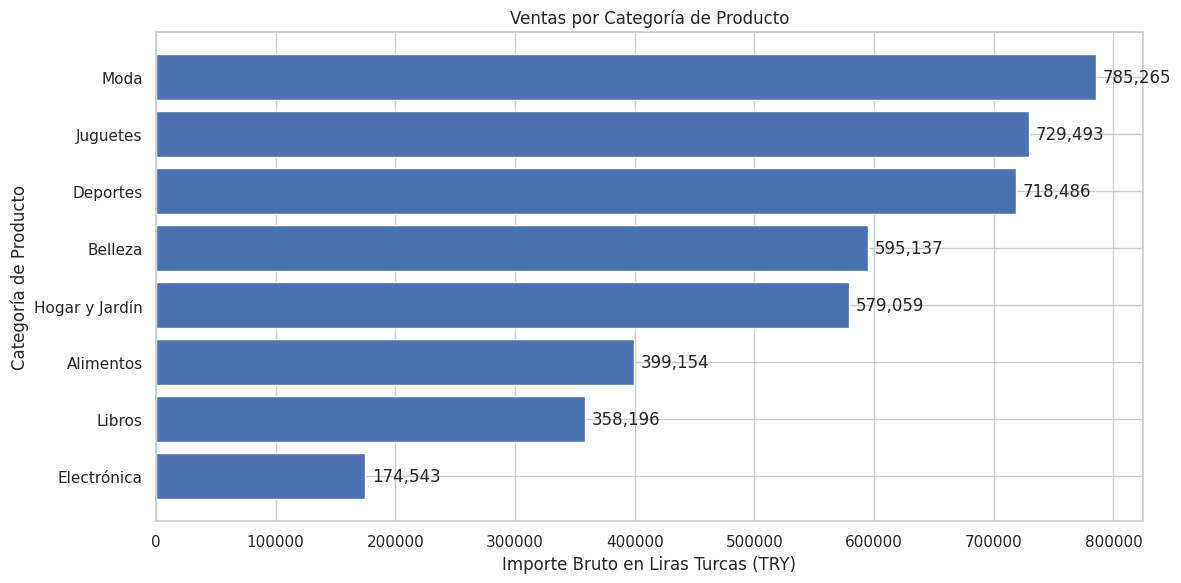

In [ ]:
# Traducción
traduccion_categorias = {
    'Fashion': 'Moda',
    'Toys': 'Juguetes',
    'Sports': 'Deportes',
    'Beauty': 'Belleza',
    'Home & Garden': 'Hogar y Jardín',
    'Food': 'Alimentos',
    'Books': 'Libros',
    'Electronics': 'Electrónica'
}
data['Categoria_producto'] = data['Categoria_producto'].replace(traduccion_categorias)

# Agrupar y sumar el importe total por categoría
data_agrupada1 = data.groupby('Categoria_producto')['Monto_Bruto'].sum().reset_index()
data_agrupada1 = data_agrupada1.sort_values(by='Monto_Bruto', ascending=True)

# Gráfico
plt.figure(figsize=(12, 6))

# Se guarda el gráfico en la variable 'barras' para poder ponerle las etiquetas luego
barras = plt.barh(y=data_agrupada1['Categoria_producto'], width=data_agrupada1['Monto_Bruto'])

# Agregar las etiquetas numéricas a las barras
plt.bar_label(barras, labels=[f'{x:,.0f}' for x in data_agrupada1['Monto_Bruto']], padding=5)

# Títulos y etiquetas
plt.xlabel('Importe Bruto en Liras Turcas (TRY)')
plt.ylabel('Categoría de Producto')
plt.title('Ventas por Categoría de Producto')

# Ajustar los márgenes para que no se corten las etiquetas de los extremos
plt.tight_layout()
plt.show()

## Análisis de dispersión del `Importe` según el `Tipo de Dispositivo` y `Método de pago`

In [ ]:
data['Tipo_dispositivo'].value_counts()

,count
Tipo_dispositivo,
Mobile,6500
Desktop,3928
Tablet,1130


In [ ]:
data['Metodo_pago'].value_counts()

,count
Metodo_pago,
Credit Card,4563
Debit Card,2987
Digital Wallet,2191
Bank Transfer,1175
Cash on Delivery,642


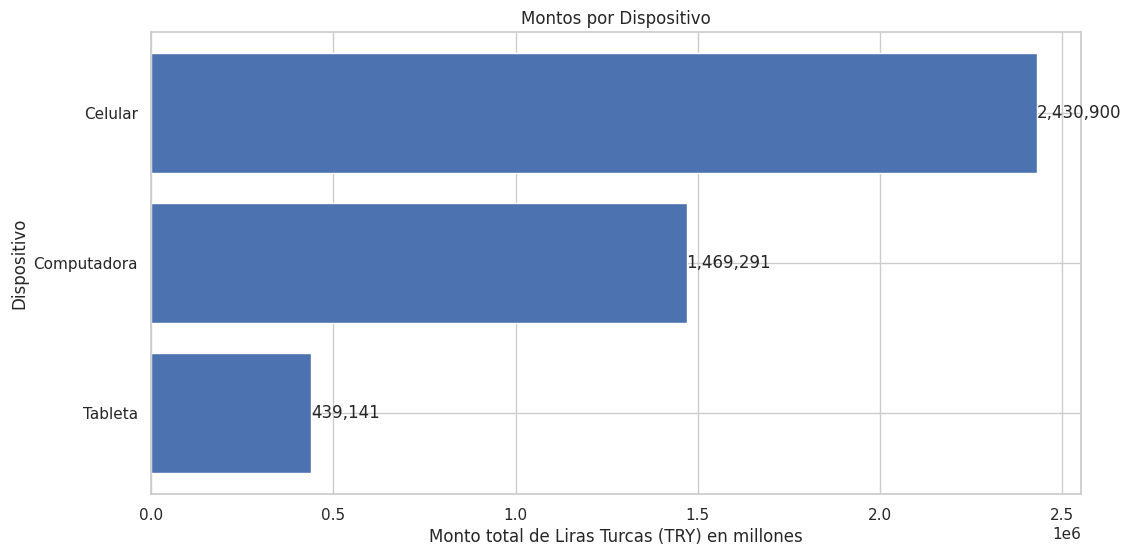

In [ ]:
# Agrupar y sumar compras por Método de pago
data_agrupada4 = data.groupby('Tipo_dispositivo')['Monto_Bruto'].sum().reset_index()

data_agrupada4 = data_agrupada4.sort_values(by='Monto_Bruto', ascending=True)

# Traducción
traduccion_dispositivos = {
    'Mobile': 'Celular',
    'Desktop': 'Computadora',
    'Tablet': 'Tableta'}

# Aplicar la traducción a la columna
data_agrupada4['Tipo_dispositivo'] = data_agrupada4['Tipo_dispositivo'].replace(traduccion_dispositivos)

# Graficar usando los datos ya agrupados
plt.figure(figsize=(12, 6))
barras = plt.barh(y = data_agrupada4['Tipo_dispositivo'], width = data_agrupada4['Monto_Bruto'])

plt.bar_label(barras, labels=[f'{x:,.0f}' for x in data_agrupada4['Monto_Bruto']])
plt.xlabel('Monto total de Liras Turcas (TRY) en millones')
plt.ylabel('Dispositivo')
plt.title('Montos por Dispositivo')
plt.show()

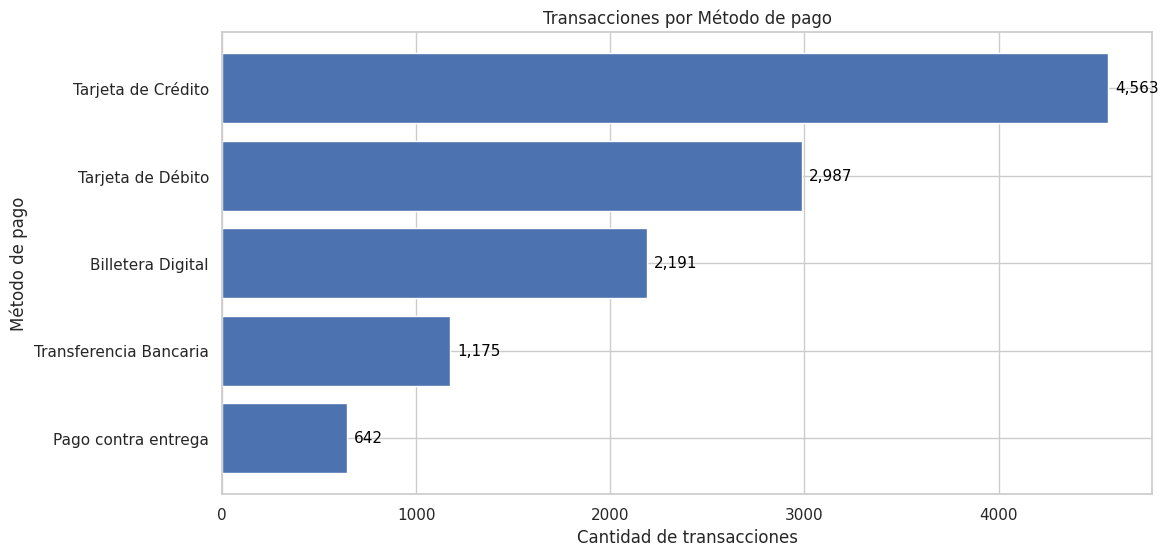

In [ ]:
# Agrupar y contar transacciones por Método de pago
data_agrupada5 = data.groupby('Metodo_pago').size().reset_index(name='Transacciones')

# Traducción
traduccion_metodos = {
    'Credit Card': 'Tarjeta de Crédito',
    'Debit Card': 'Tarjeta de Débito',
    'Digital Wallet': 'Billetera Digital',
    'Bank Transfer': 'Transferencia Bancaria',
    'Cash on Delivery': 'Pago contra entrega'}

# Aplicar la traducción a la columna y dataframe correctos
data_agrupada5['Metodo_pago'] = data_agrupada5['Metodo_pago'].replace(traduccion_metodos)

# Ordenar los datos por la nueva columna
data_agrupada5 = data_agrupada5.sort_values(by='Transacciones', ascending=True)

# Graficar usando los datos ya agrupados
plt.figure(figsize=(12, 6))

# 'Transacciones' en el ancho de las barras
barras = plt.barh(y=data_agrupada5['Metodo_pago'], width=data_agrupada5['Transacciones'])

# Usar plt.bar_label para imprimir los números
plt.bar_label(barras, labels=[f'{x:,.0f}' for x in data_agrupada5['Transacciones']], padding=5, color='black', fontsize=11)

# Actualizar la etiqueta del ejes
plt.xlabel('Cantidad de transacciones')
plt.ylabel('Método de pago')
plt.title('Transacciones por Método de pago')
plt.show()

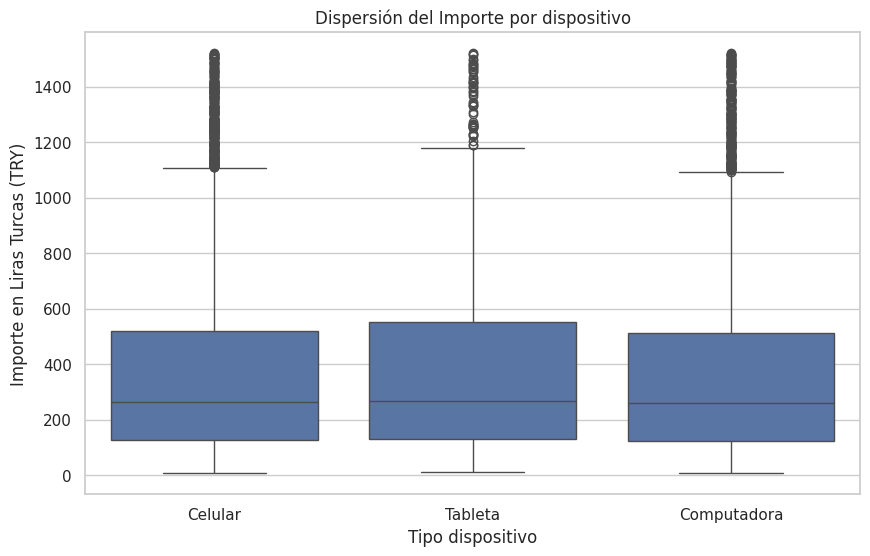

In [ ]:
traduccion_dispositivos = {
    'Mobile': 'Celular',
    'Desktop': 'Computadora',
    'Tablet': 'Tableta'
}
data['Tipo_dispositivo'] = data['Tipo_dispositivo'].replace(traduccion_dispositivos)

plt.figure(figsize=(10, 6))
sns.boxplot(data=data, y='Monto_Bruto', x='Tipo_dispositivo')

plt.xlabel('Tipo dispositivo')
plt.ylabel('Importe en Liras Turcas (TRY)')
plt.title('Dispersión del Importe por dispositivo')
plt.show()

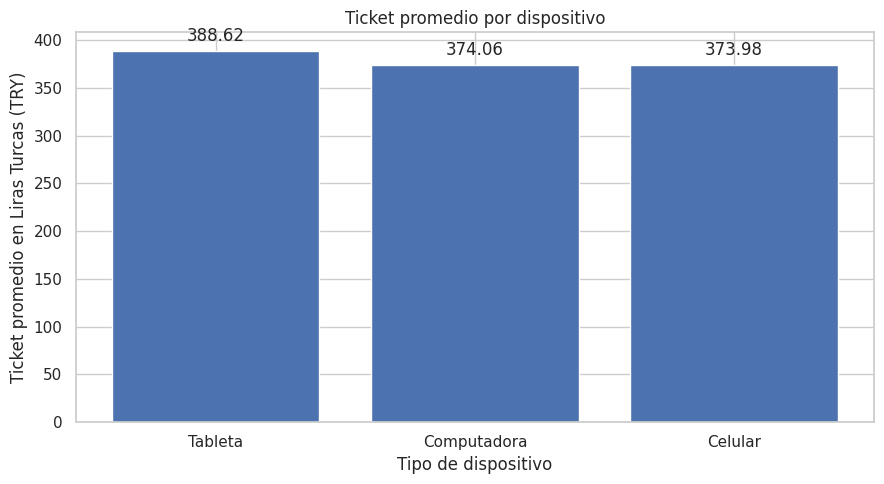

In [ ]:
# Cálculo ticket promedio por dispositivo
ticket_dispositivo = data.groupby('Tipo_dispositivo')['Monto_Bruto'].mean().reset_index()

# Opcional: Ordenar los datos de mayor a menor para una mejor visualización
ticket_dispositivo = ticket_dispositivo.sort_values(by='Monto_Bruto', ascending=False)

# Gráfico
plt.figure(figsize=(9, 5))

barras = plt.bar(
    ticket_dispositivo['Tipo_dispositivo'],
    ticket_dispositivo['Monto_Bruto'],
    color='#4C72B0' # Manteniendo la consistencia de color
)

plt.bar_label(
    barras,
    labels=[f'{x:,.2f}' for x in ticket_dispositivo['Monto_Bruto']],
    padding=4
)

plt.title('Ticket promedio por dispositivo')
plt.xlabel('Tipo de dispositivo')
plt.ylabel('Ticket promedio en Liras Turcas (TRY)')

plt.tight_layout()
plt.show()

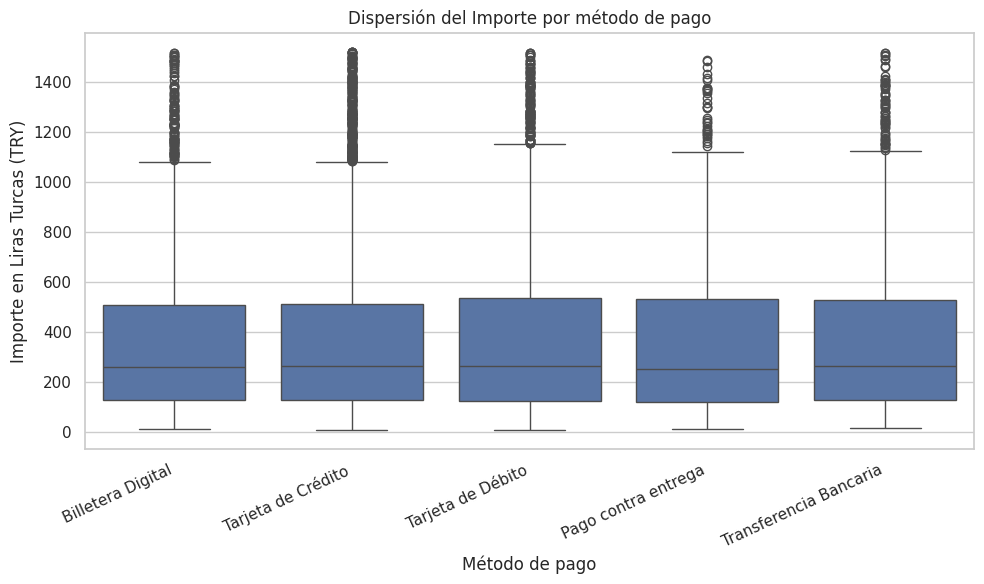

In [ ]:
# 1. Traducción
traduccion_metodos = {
    'Credit Card': 'Tarjeta de Crédito',
    'Debit Card': 'Tarjeta de Débito',
    'Digital Wallet': 'Billetera Digital',
    'Bank Transfer': 'Transferencia Bancaria',
    'Cash on Delivery': 'Pago contra entrega'
}
data['Metodo_pago'] = data['Metodo_pago'].replace(traduccion_metodos)

plt.figure(figsize=(10, 6))

sns.boxplot(data=data, y='Monto_Bruto', x='Metodo_pago')

plt.xlabel('Método de pago')
plt.ylabel('Importe en Liras Turcas (TRY)')
plt.title('Dispersión del Importe por método de pago')

# Rotar las etiquetas del eje X para evitar que se amontonen
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# Conversión a tipo de dato Fecha a Tiempo
data['Fecha'] = pd.to_datetime(data['Fecha'])

print(data['Fecha'].dtype)

datetime64[ns]


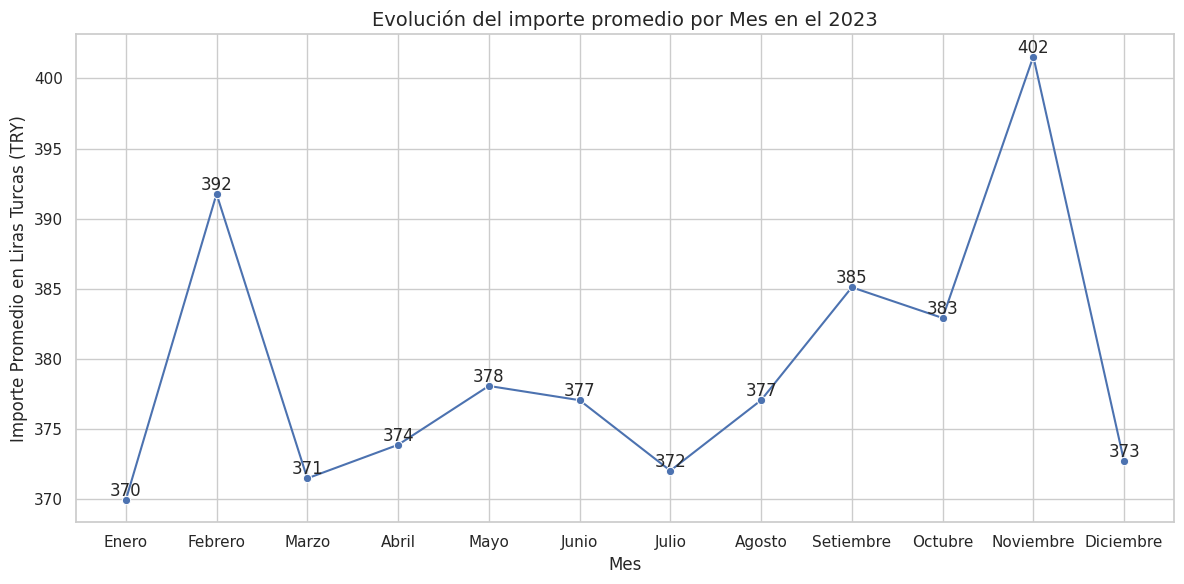

In [ ]:
# Filtrar y preparar los datos iniciales
data_2023 = data[data['Fecha'].dt.year == 2023].copy()
data_2023['Month'] = data_2023['Fecha'].dt.month_name()

# Agrupar
importe_mes = data_2023.groupby("Month")["Monto_Bruto"].mean().reset_index()

# 1. Definir la traducción
traduccion_meses = {
    'January': 'Enero', 'February': 'Febrero', 'March': 'Marzo',
    'April': 'Abril', 'May': 'Mayo', 'June': 'Junio',
    'July': 'Julio', 'August': 'Agosto', 'September': 'Setiembre',
    'October': 'Octubre', 'November': 'Noviembre', 'December': 'Diciembre'}

# traducción
importe_mes['Month'] = importe_mes['Month'].replace(traduccion_meses)

# Definir el orden cronológico
orden_meses_espanol = [
    'Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
    'Julio', 'Agosto', 'Setiembre', 'Octubre', 'Noviembre', 'Diciembre']

# 4. Aplicar la categoría y ordenar usando la lista en español
importe_mes['Month'] = pd.Categorical(importe_mes['Month'], categories=orden_meses_espanol, ordered=True)
importe_mes = importe_mes.sort_values('Month')

# Gráfico
plt.figure(figsize=(12, 6))
sns.lineplot(
    data = importe_mes,
    x = "Month",
    y = "Monto_Bruto",
    marker = "o"
)

# Etiquetas de datos
for i, valor in enumerate(importe_mes['Monto_Bruto']):
    plt.text(i, valor, f'{valor:,.0f}', ha='center', va='bottom')

# Títulos y formato del gráfico
plt.title("Evolución del importe promedio por Mes en el 2023", fontsize=14)
plt.xlabel("Mes")
plt.ylabel("Importe Promedio en Liras Turcas (TRY)")

plt.tight_layout()
plt.show()

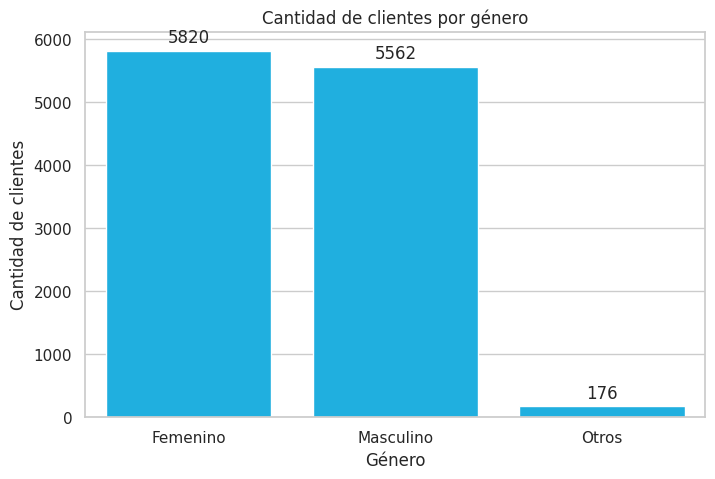

In [ ]:
# 1. Traducir los valores al español
traduccion_genero = {'Male': 'Masculino', 'Female': 'Femenino', 'Other': 'Otros'}
data['Genero'] = data['Genero'].replace(traduccion_genero)

# 2. Generar el gráfico con la base de datos original
plt.figure(figsize=(8,5))
ax = sns.countplot(
    x="Genero",
    data=data,
    order=data["Genero"].value_counts().index,
    color="deepskyblue"
)

plt.title("Cantidad de clientes por género")
plt.ylabel("Cantidad de clientes")
plt.xlabel("Género")

ax.bar_label(ax.containers[0], padding=3)

plt.show()

Se aprecia una ligera mayor representación del género femenino respecto al masculino, la categoría "Otros" presenta una participación considerablemente menor.

El grupo de mujeres concentra 5820 clientes (50.36%), mientras que el de varones registra 5562 clientes (48.12%), la categoría "Other" tiene 176 clientes (1.5%).

       Genero             Metodo_pago  count
0    Femenino       Billetera Digital   1116
1    Femenino     Pago contra entrega    327
2    Femenino      Tarjeta de Crédito   2281
3    Femenino       Tarjeta de Débito   1511
4    Femenino  Transferencia Bancaria    585
5   Masculino       Billetera Digital   1041
6   Masculino     Pago contra entrega    306
7   Masculino      Tarjeta de Crédito   2215
8   Masculino       Tarjeta de Débito   1429
9   Masculino  Transferencia Bancaria    571
10      Otros       Billetera Digital     34
11      Otros     Pago contra entrega      9
12      Otros      Tarjeta de Crédito     67
13      Otros       Tarjeta de Débito     47
14      Otros  Transferencia Bancaria     19


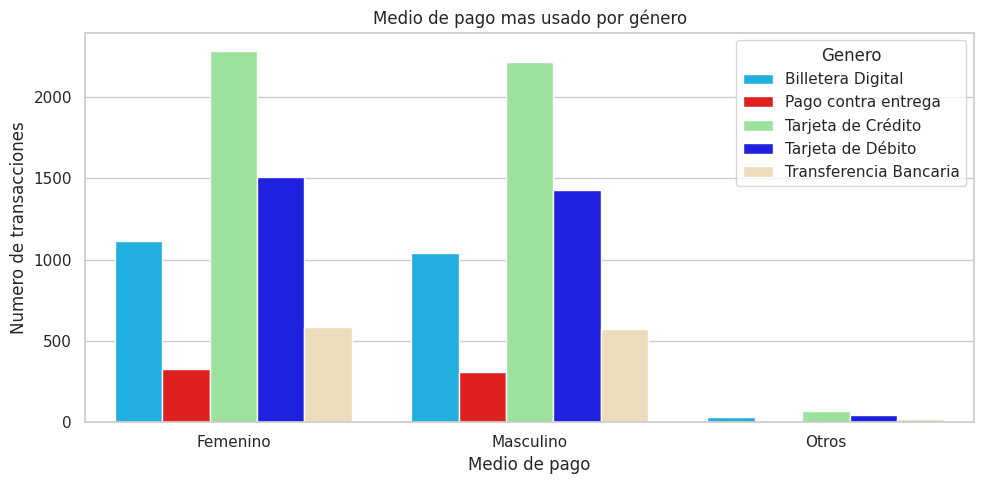

In [ ]:
conteo = data.groupby(["Genero","Metodo_pago"]).size().reset_index(name = "count")
print(conteo)

plt.figure(figsize = (10,5))

sns.barplot(x="Genero", y="count", hue="Metodo_pago", data = conteo, palette = ["deepskyblue", "red","lightgreen", "blue", "wheat"])

plt.title("Medio de pago mas usado por género")
plt.xlabel("Medio de pago")
plt.ylabel("Numero de transacciones")
plt.legend(title="Genero")
plt.tight_layout()
plt.show()

En cuanto a los medios de pago, la tarjeta de crédito es el medio más utilizado tanto por el genero Masculino como por el Femenino, seguida de la tarjeta de débito. La billetera digital presenta una participación intermedia, mientras que la transferencia bancaria y el pago contra entrega registran los menores niveles de uso.



## Conclusión

Se seleccionó Total_Amount (Monto_Total) y se transformó a Importe_Bruto como variable target porque representa el valor económico antes de descuento de cada transacción y, al ser una variable cuantitativa continua, permite plantear posteriormente un problema de regresión orientado a estimar el importe de compra.
Previamente, se realizó una depuración mediante el método IQR, reduciendo la base de 17,049 a 11,558 registros. A partir del análisis exploratorio se obtuvieron tres hallazgos principales. Primero, Product_Category presenta diferencias claras en el ticket promedio, destacando Electronics con aproximadamente 803 TRY, seguida por Home & Garden y Sports. Segundo, en la matriz de correlación, Precio_unitario presenta la mayor relación lineal con Monto_Bruto (r ≈ 0.697), mientras que Duracion_sesion_web_min (r ≈ -0.013) y Paginas_vistas (r ≈ 0.003) muestran relaciones lineales prácticamente nulas. Tercero, al analizar el ticket promedio por dispositivo, Tablet presenta un valor ligeramente mayor, cercano a 381 TRY, mientras que Desktop y Mobile se encuentran alrededor de 366 TRY, evidenciando que las diferencias entre dispositivos son reducidas.
En conjunto, el EDA permitió identificar qué variables presentan mayor asociación con el importe de compra y cuáles muestran poca relación lineal. Como siguiente etapa analítica se propone aplicar Regresión Lineal, considerando que la variable objetivo es cuantitativa continua. Esta propuesta corresponde a una etapa posterior de modelamiento; en el presente análisis el objetivo principal fue explorar, depurar y comprender el comportamiento de los datos antes de construir un modelo predictivo.